In [1]:
from google.colab import drive
drive.mount('/content/gdrive')
%cd /content/gdrive/MyDrive/estruturas

Mounted at /content/gdrive
/content/gdrive/MyDrive/estruturas


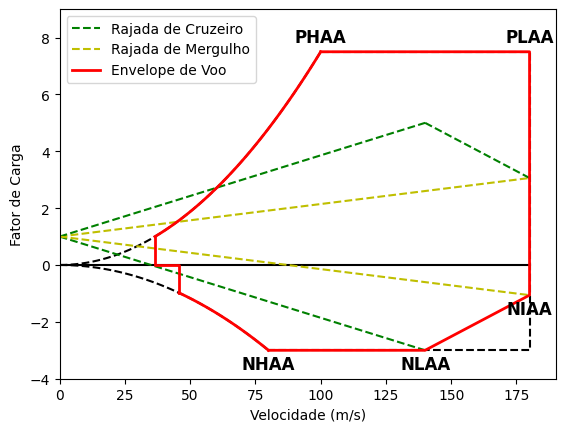

Distribuição de Sustentação e Arrasto ao longo da Semi-Envergadura


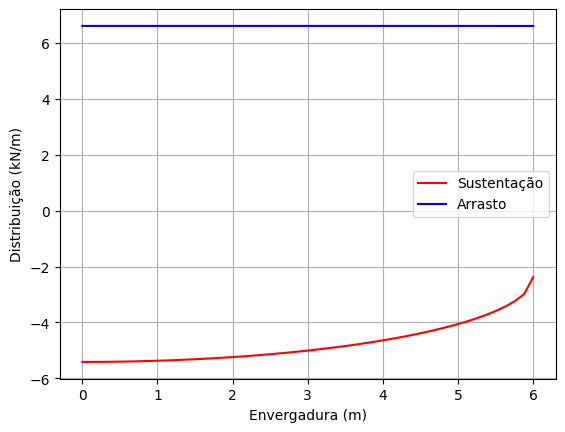

Decomposição da Distribuição dos Esforços ao longo da Semi-Envergadura


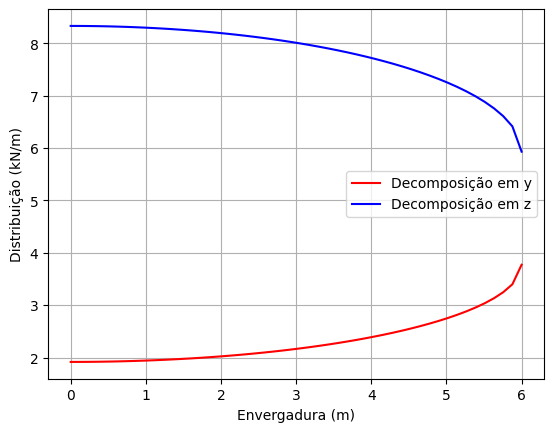

Esforço Cortante ao longo da Semi-Envergadura


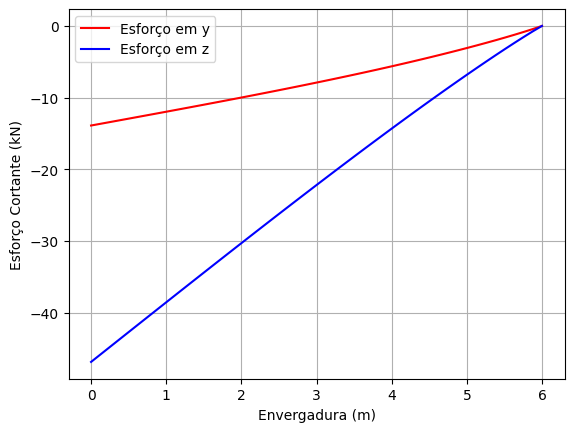

Momento Fletor ao longo da Semi-Envergadura


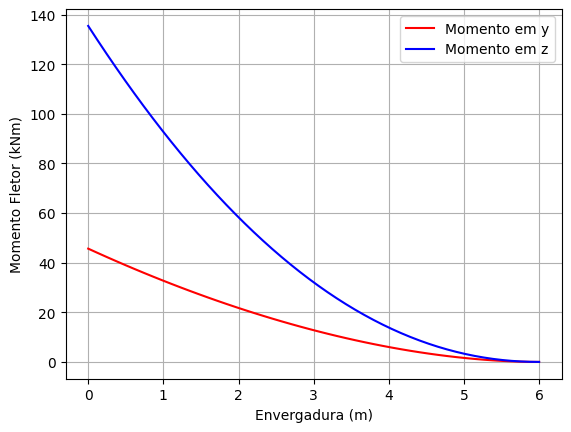

Área ponderada: 0.7143 m²

Posição y centroide ponderado: 1.05 m
Posição z centroide ponderado: 0.3 m
Momento de inércia Iyy*: 0.0287 kgm²
Momento de inércia Izz*: 0.3292 kgm²
Produto de inércia Iyz*: 0 kgm²
Ângulo do Eixo Neutro: 104.5 °


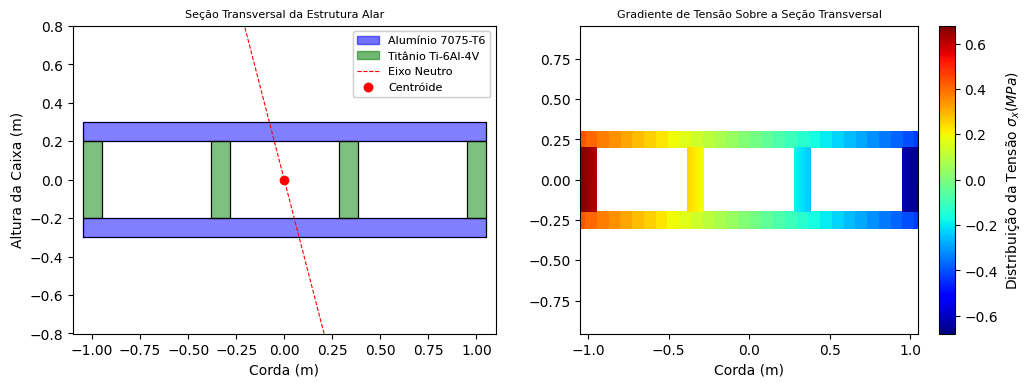

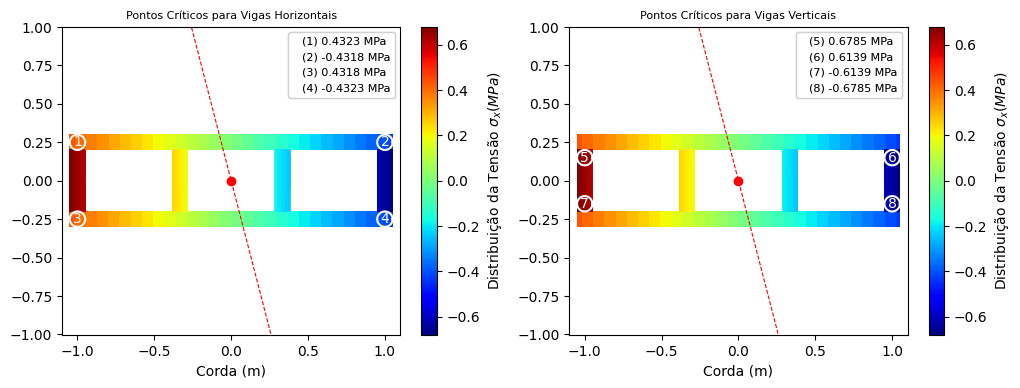

Tensão máxima positiva: 0.6794 MPa
Tensão máxima negativa: -0.6794 MPa
Deflexão no eixo y e z em função da semi envergadura


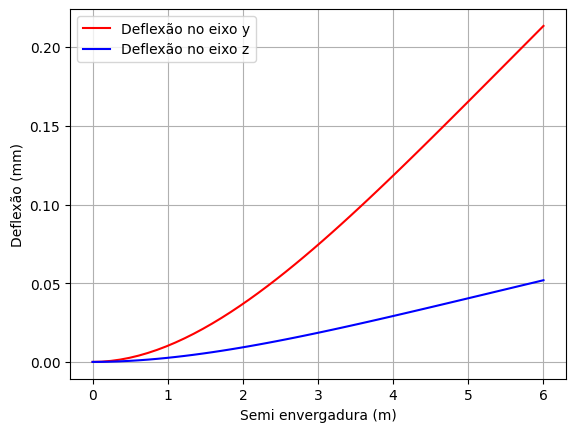

Deflexão máxima em y: 0.2134 mm
Deflexão máxima em z: 0.0519 mm


In [6]:
#@title codigo
class parametros_analise:
        
    def __init__(self,condicao,dimensoes,mtow):
        
        self.dim_enverg = dimensoes[0]
        self.dim_corda = dimensoes[1]
        self.esp_1 = dimensoes[2]
        self.esp_2 = dimensoes[3]
        self.esp_3 = dimensoes[4]
        self.dim_h = dimensoes[5]
        self.mtow = mtow
        
        #Escolha da condição do V-n
        if condicao == 1:
            self.fator_carga = 7.5
            self.alpha = 22
            self.velocidade = 100
        elif condicao == 2:
            self.fator_carga = 7.5
            self.alpha = 8
            # self.alpha = 0
            self.velocidade = 180
        elif condicao == 3:
            self.fator_carga = -3
            self.alpha = -19
            self.velocidade = 80
        elif condicao == 4:
            self.fator_carga = -3
            self.alpha = -8.7
            self.velocidade = 140
        elif condicao == 5:
            self.fator_carga = -1.06
            self.alpha = -3.8
            self.velocidade = 180
    
    def material_1(self):
        self.modulo_elasticidade = 70e9
        self.coef_poisson = 0.3
        self.tensao_escoamento = 400e6 
        return self.modulo_elasticidade, self.coef_poisson, self.tensao_escoamento

    def material_2(self):
        self.modulo_elasticidade = 110e9
        self.coef_poisson = 0.3
        self.tensao_escoamento = 1100e6 
        return self.modulo_elasticidade, self.coef_poisson, self.tensao_escoamento
         
import PARAMETROS
import RESULTADOS
import VN
from AERODINAMICA import calculos_aerodinamica
from google.colab import output
from PROPRIEDADES_AREA import A_pond, centroide_pond, I_pond

densidade = 1
gravidade = 9.80665
cd0 = 0.017 
k = 0.021 

condicao = int(input(f'Selecione qual das condições você deseja calcular: \n\n{" ":>4}(1) PHAA \n{" ":>4}(2) PLAA\n{" ":>4}(3) NHAA\n{" ":>4}(4) NIAA\n{" ":>4}(5) NLAA\n{" ":>4}\n'))
output.clear()
dim_enverg = float(input('Digite a dimensão da envergadura b [m]:  \n'))
output.clear()
dim_corda = float(input('Digite a dimensão da corda c [m]:   \n')) 
output.clear()
dim_h = float(input('Digite a dimensão da altura da caixa h [m]:   \n')) 
output.clear()
esp_1 = float(input('Digite a espessura t1 [m]:  \n'))
output.clear()
esp_2 = float(input('Digite a espessura t2 [m]:  \n'))
output.clear()
esp_3 = float(input('Digite a espessura t3 [m]:  \n'))
output.clear()
mtow = float(input('Digite o peso máximo de decolagem [Kg]:  \n'))
output.clear()

dimensoes = [dim_enverg, dim_corda, esp_1, esp_2, esp_3, dim_h]
inputs = parametros_analise(condicao,dimensoes,mtow)

PARAMETROS.GRAVIDADE = gravidade
PARAMETROS.DENSIDADE = densidade
PARAMETROS.CD0 = cd0 
PARAMETROS.K = k 
PARAMETROS.FATOR_CARGA = inputs.fator_carga 
PARAMETROS.ALPHA = inputs.alpha
PARAMETROS.VELOCIDADE = inputs.velocidade 
PARAMETROS.MODULO_ELASTICIDADE_1, PARAMETROS.COEF_POISSON_1, PARAMETROS.TENSAO_ESCOAMENTO_1 = inputs.material_1()
PARAMETROS.MODULO_ELASTICIDADE_2, PARAMETROS.COEF_POISSON_2, PARAMETROS.TENSAO_ESCOAMENTO_2 = inputs.material_2()
PARAMETROS.DIM_ENVERG = inputs.dim_enverg
PARAMETROS.DIM_CORDA = inputs.dim_corda
PARAMETROS.DIM_H = inputs.dim_h
PARAMETROS.ESP_1 = inputs.esp_1
PARAMETROS.ESP_2 = inputs.esp_2
PARAMETROS.ESP_3 = inputs.esp_3
PARAMETROS.MTOW = inputs.mtow

#Cálculos aerodinâmicos
L, D, _, _, _ = calculos_aerodinamica()
VN.vn()

#Plots das cargas externas
import PLOTS
PLOTS.sust_arrast();
PLOTS.cargas();

#Plots diagramas dos esforços internos
PLOTS.esforco_cortante();
My, Mz = PLOTS.momento_fletor()
RESULTADOS.MY, RESULTADOS.MZ = My, Mz

#Cálculo área ponderada
area_ponderada = A_pond()
print(f"Área ponderada: {area_ponderada:.4} m²\n")

#Cálculo do centroide ponderado
y0_pond, z0_pond = centroide_pond()
RESULTADOS.Y0_POND, RESULTADOS.Z0_POND = y0_pond, z0_pond 
print(f'Posição y centroide ponderado: {y0_pond:.4} m\nPosição z centroide ponderado: {z0_pond:.4} m')

#Cálculo momentos e produto de inércia ponderados
Iyy_pond, Izz_pond, Iyz_pond = I_pond()
RESULTADOS.IYY_POND, RESULTADOS.IZZ_POND, RESULTADOS.IYZ_POND = Iyy_pond, Izz_pond, Iyz_pond
print(f'Momento de inércia Iyy*: {Iyy_pond:.4} kgm²\nMomento de inércia Izz*: {Izz_pond:.4} kgm²\nProduto de inércia Iyz*: {Iyz_pond} kgm²')

#Identificação do eixo neutro
from EIXO_NEUTRO import angulo_eixo_neutro
ang_neut = angulo_eixo_neutro()
RESULTADOS.ANG_NEUT = ang_neut
print(f'Ângulo do Eixo Neutro: {(ang_neut+90):.4} °')

#Distribuição das tensões em pontos críticos
import TENSAO 
v_max, v_min = TENSAO.dist_tensao()
print(f'Tensão máxima positiva: {(v_max/1e6):.4} MPa\nTensão máxima negativa: {(v_min/1e6):.4} MPa')

#Cálculo das deflexões
import DEFLEXAO 
d_maxy, d_maxz = DEFLEXAO.calc_deflexao()
print(f'Deflexão máxima em y: {(d_maxy*1e3):.4} mm\nDeflexão máxima em z: {(d_maxz*1e3):.4} mm')
